In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)

# 1. Read the dataset

In [ ]:
DATA_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"
df = pd.read_csv(DATA_URL)
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [ ]:
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")
display(df.sample(5, random_state=42))

Rows: 344
Columns: 7


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
194,Chinstrap,Dream,50.9,19.1,196.0,3550.0,MALE
157,Chinstrap,Dream,45.2,17.8,198.0,3950.0,FEMALE
225,Gentoo,Biscoe,46.5,13.5,210.0,4550.0,FEMALE
208,Chinstrap,Dream,45.2,16.6,191.0,3250.0,FEMALE
318,Gentoo,Biscoe,48.4,14.4,203.0,4625.0,FEMALE


In [ ]:
df["species"].value_counts()

,count
species,
Adelie,152
Gentoo,124
Chinstrap,68


In [ ]:
# dataframe with just single type of penguin species
sub_df = df[df['species']== "Adelie"]
sub_df.__len__()

152

In [ ]:
display(df.dtypes.to_frame("data_type"))
display(df.isna().sum().to_frame("missing_values"))

,data_type
species,object
island,object
bill_length_mm,float64
bill_depth_mm,float64
flipper_length_mm,float64
body_mass_g,float64
sex,object


,missing_values
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11


In [ ]:
numeric_columns = [
    "bill_length_mm", "bill_depth_mm",
    "flipper_length_mm", "body_mass_g"
]
df[numeric_columns].describe().round(2)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.00,342.00,342.00,342.00
mean,43.92,17.15,200.92,4201.75
std,5.46,1.97,14.06,801.95
min,32.10,13.10,172.00,2700.00
25%,39.22,15.60,190.00,3550.00
50%,44.45,17.30,197.00,4050.00
75%,48.50,18.70,213.00,4750.00
max,59.60,21.50,231.00,6300.00


# 2. Cleaning choice for this lesson

We will remove rows missing any variable used in the lesson. This keeps the code simple.

In [ ]:
analysis_columns = numeric_columns + ["species", "island", "sex"]
penguins = df[analysis_columns].dropna().copy()

print(f"Rows before cleaning: {len(df)}")
print(f"Rows after cleaning:  {len(penguins)}")
print(f"Rows removed:         {len(df) - len(penguins)}")

Rows before cleaning: 344
Rows after cleaning:  333
Rows removed:         11


# 3. Begin with the bivariate view
Question: Do penguins with longer flippers tend to be heavier?

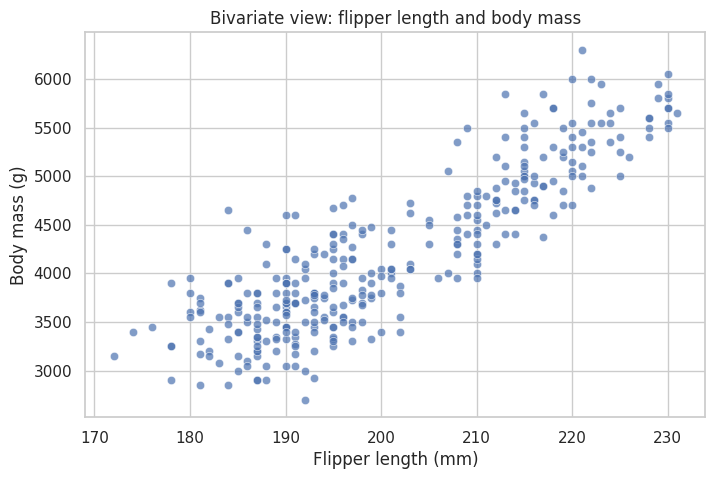

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=penguins, x="flipper_length_mm", y="body_mass_g", alpha=0.7)
plt.title("Bivariate view: flipper length and body mass")
plt.xlabel("Flipper length (mm)")
plt.ylabel("Body mass (g)")
plt.show()

In [ ]:
df["flipper_length_mm"].corr(df['body_mass_g'])

np.float64(0.8712017673060111)

In [ ]:
df.loc[df["species"]=='Adelie', "flipper_length_mm"].corr(df.loc[df["species"]=='Adelie', "body_mass_g"])
# df[df["species"] == "Adelie"]["flipper_length_mm"]

np.float64(0.4682016942179394)

# 4. Numerical overview: correlation heatmap
A heatmap gives a compact overview of linear relationships among numerical variables.

In [ ]:
correlation_matrix = penguins[numeric_columns].corr()
correlation_matrix.round(2)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.00,-0.23,0.65,0.59
bill_depth_mm,-0.23,1.00,-0.58,-0.47
flipper_length_mm,0.65,-0.58,1.00,0.87
body_mass_g,0.59,-0.47,0.87,1.00


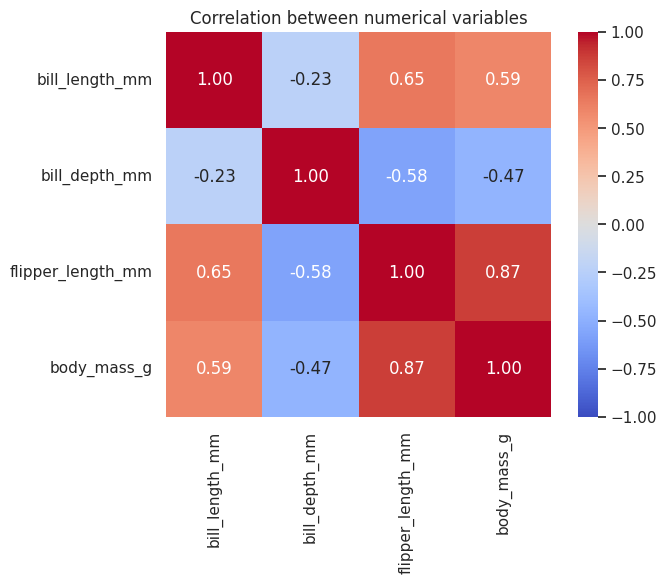

In [ ]:
plt.figure(figsize=(7, 5))
sns.heatmap(
    correlation_matrix,
    annot=True, fmt=".2f", cmap="coolwarm",
    vmin=-1, vmax=1, center=0, square=True
)
plt.title("Correlation between numerical variables")
plt.show()

# 5. Many variables at once: pairplot
The numerical measurements provide the rows and columns. Color adds species as another variable.

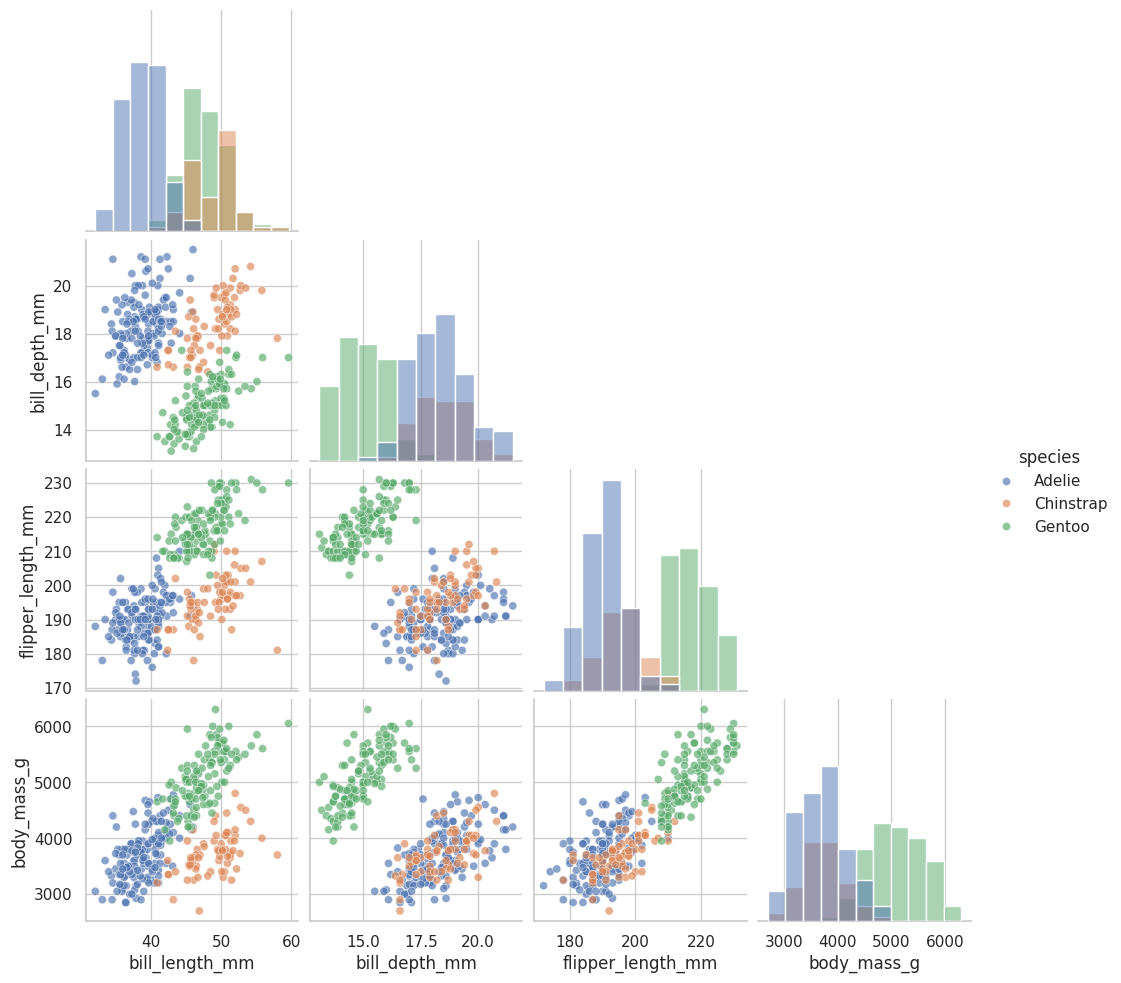

In [ ]:
sns.pairplot(
    data=penguins,
    vars=numeric_columns,
    hue="species",
    corner=True,
    diag_kind="hist",
    plot_kws={"alpha": 0.65, "s": 35}
)
plt.show()

# 6. Focused multivariate view: add species
We return to flipper length and body mass, now using color for species.

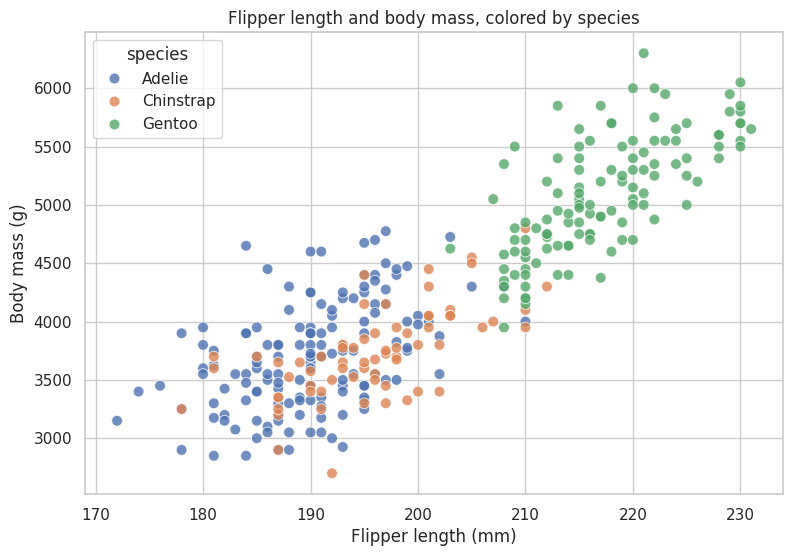

In [ ]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=penguins,
    x="flipper_length_mm", y="body_mass_g",
    hue="species", alpha=0.8, s=60
)
plt.title("Flipper length and body mass, colored by species")
plt.xlabel("Flipper length (mm)")
plt.ylabel("Body mass (g)")
plt.show()

# 7. Add a fourth variable using facets
Instead of putting color, marker style, and size into one crowded plot, use separate panels for sex.

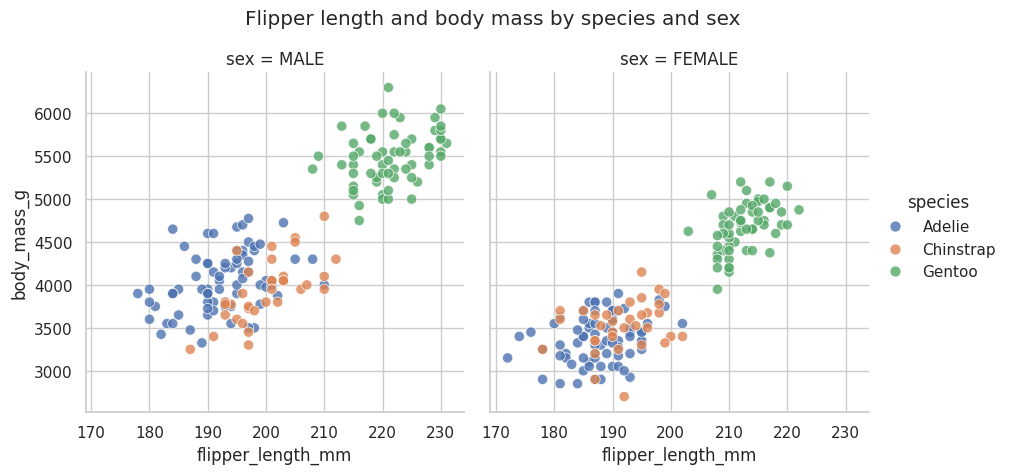

In [ ]:
# relational plot
sns.relplot(
    data=penguins,
    x="flipper_length_mm", y="body_mass_g",
    hue="species", col="sex",
    kind="scatter", height=4.5, aspect=1,
    alpha=0.8, s=55
)
plt.suptitle("Flipper length and body mass by species and sex", y=1.05)
plt.show()

# 8. Exact group comparisons
A plot shows shape and overlap. A table gives exact values and group sizes.

In [ ]:
group_summary = (
    penguins.groupby(["species", "sex"], observed=True)["body_mass_g"]
    .agg(count="count", mean="mean", median="median")
    .round(1)
)
group_summary

count    mean  median
species   sex                          
Adelie    FEMALE     73  3368.8  3400.0
          MALE       73  4043.5  4000.0
Chinstrap FEMALE     34  3527.2  3550.0
          MALE       34  3939.0  3950.0
Gentoo    FEMALE     58  4679.7  4700.0
          MALE       61  5484.8  5500.0

In [ ]:
mass_pivot = pd.pivot_table(
    penguins,
    index="species", columns="sex",
    values="body_mass_g", aggfunc="median",
    observed=True
).round(0)
mass_pivot

sex,FEMALE,MALE
species,,
Adelie,3400.0,4000.0
Chinstrap,3550.0,3950.0
Gentoo,4700.0,5500.0


# 9. Overall relationship versus within-species relationships
The overall flipper-length/body-mass relationship combines differences between species and variation within species. Separate lines help us inspect both.

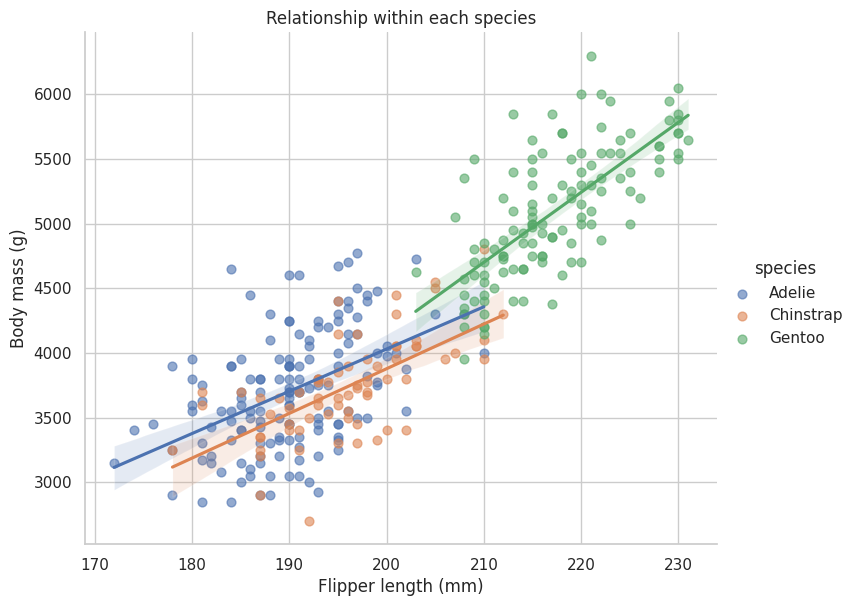

In [ ]:
# linear model plot (scatterplot + regression line)
sns.lmplot(
    data=penguins,
    x="flipper_length_mm", y="body_mass_g",
    hue="species", height=6, aspect=1.25,
    scatter_kws={"alpha": 0.6, "s": 40},
    ci=95
)
plt.title("Relationship within each species")
plt.xlabel("Flipper length (mm)")
plt.ylabel("Body mass (g)")
plt.show()